In [1]:
import sklearn as sk
from sklearn import set_config
set_config(display='text')

In [2]:
import platform
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.font_manager as fm
import warnings
warnings.filterwarnings('ignore')


# OS에 따라서 폰트 로드
os_name = platform.system()

if os_name == 'Linux':
    # 리눅스용 폰트 로드
    plt.rc('font', family='NanumGothicCoding')
    print("(리눅스) 한글폰트 로드 완료")

elif os_name == 'Windows':
    # 윈도우용 폰트 로드
    font_path = 'C:\\Windows\\Fonts\\malgun.ttf'
    font = fm.FontProperties(fname=font_path).get_name()
    mpl.rc('font', family=font)
    print("(윈도우) 한글폰트 로드 완료")

elif os_name == 'Darwin':
    # 맥용 폰트 로드
    plt.rc('font', family='AppleGothic')
    print("(맥) 한글폰트 로드 완료")

else:
    print(f"알 수 없는 OS입니다: {os_name}")

# 마이너스 기호 깨짐 방지
mpl.rcParams['axes.unicode_minus'] = False

(윈도우) 한글폰트 로드 완료


In [3]:
import pandas as pd
data = pd.read_csv('./AICE Associate 샘플문항_분류/wine_quality_data.csv')
data.head(4)

,Grade,E_title,E_country,E_province,E_region_1,E_region_2,E_winery,E_FE_vintage,E_wine_variety,E_FE_wine_kind,FE_continent,E_price,FE_points_location,FE_points_variety,FE_points_winery
0,Fail,Nicosia 2013 Vulkà Bianco (Etna),Italy,Sicily & Sardinia,Etna,-,Nicosia,2013,White Blend,white,0,NaN,90.0,87.0,87.0
1,Fail,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portugal,Douro,-,-,Quinta dos Avidagos,2011,Port,NaN,0,15.0,89.0,88.0,87.0
2,Fail,St. Julian 2013 Reserve Late Harvest Riesling ...,US,Michigan,Lake Michigan Shore,-,St. Julian,2013,Riesling,white|sparkling,1,13.0,86.0,90.0,86.0
3,Fail,Tandem 2011 Ars In Vitro Tempranillo-Merlot (N...,Spain,Northern Spain,Navarra,-,Tandem,2011,Merlot,red|rose|sparkling,0,15.0,86.0,87.0,87.0


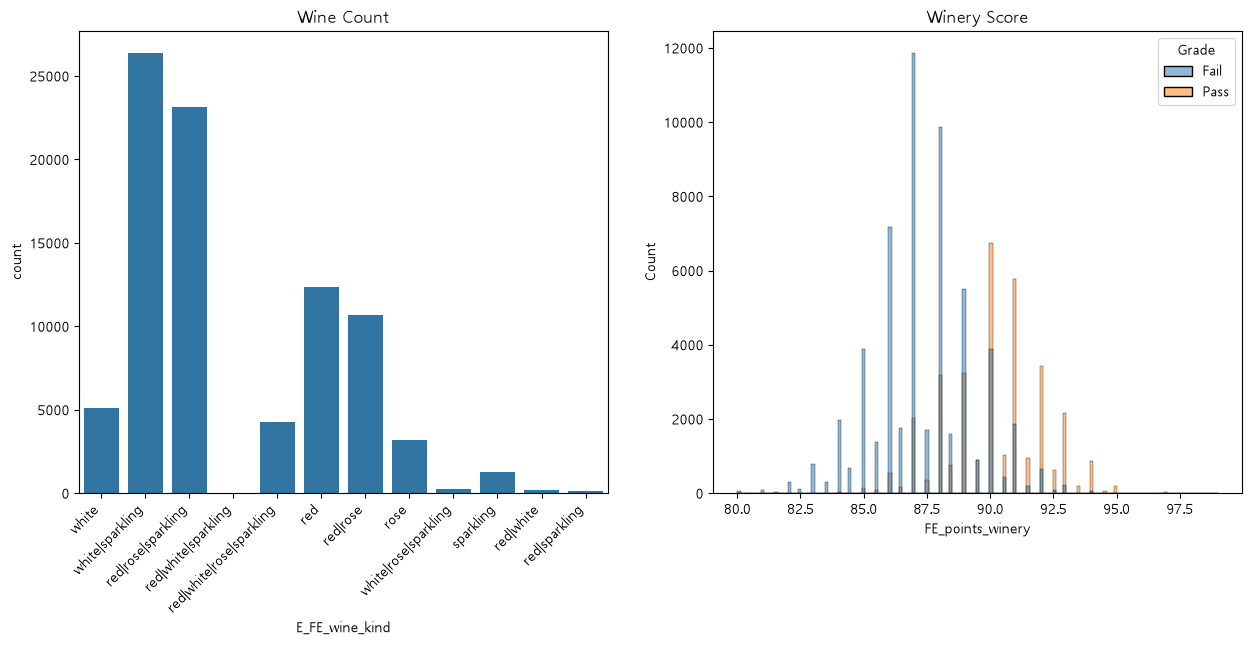

In [4]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15,6))

sns.countplot(data=data, x='E_FE_wine_kind', ax=axes[0])
sns.histplot(data=data, x='FE_points_winery', hue='Grade', ax=axes[1])

plt.setp(axes[0].get_xticklabels(), rotation=45, ha='right')

axes[0].set_title('Wine Count')
axes[1].set_title('Winery Score')

plt.show()

<Axes: xlabel='Grade', ylabel='FE_points_winery'>

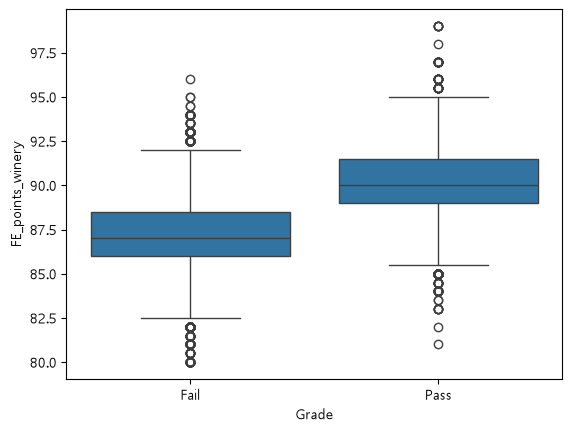

In [5]:
sns.boxplot(data=data, x='Grade', y='FE_points_winery')

In [6]:
q1 = data['FE_points_winery'].quantile(0.25)
q3 = data['FE_points_winery'].quantile(0.75)
iqr = q3 - q1

upper_fence = q3 + 1.5 * iqr
lower_fence = q1 - 1.5 * iqr

data_temp = data.drop(data[(data['FE_points_winery'] > upper_fence)|(data['FE_points_winery'] < lower_fence)].index, axis=0)
data_temp = data_temp.drop(['E_title'], axis=1)
data_temp.reset_index(drop=True, inplace=True)


In [7]:
print('결측치 제거 전', data_temp.isnull().sum())
data_na = data_temp.dropna()
print('결측치 제거 후', data_na.isnull().sum())

결측치 제거 전 Grade                    0
E_country                0
E_province               0
E_region_1               0
E_region_2               0
E_winery                 0
E_FE_vintage             0
E_wine_variety           0
E_FE_wine_kind        3746
FE_continent             0
E_price               6902
FE_points_location       0
FE_points_variety        0
FE_points_winery         0
dtype: int64
결측치 제거 후 Grade                 0
E_country             0
E_province            0
E_region_1            0
E_region_2            0
E_winery              0
E_FE_vintage          0
E_wine_variety        0
E_FE_wine_kind        0
FE_continent          0
E_price               0
FE_points_location    0
FE_points_variety     0
FE_points_winery      0
dtype: int64


In [8]:
data_na.loc[data['E_FE_wine_kind'].isin(['white|rose|sparkling','red|white|sparkling', 'red|white|rose|sparkling', 'red|sparkling']),['E_FE_wine_kind']] = 'sparkling'
data_na.loc[data['E_FE_wine_kind'].isin(['white|sparkling']),['E_FE_wine_kind']] = 'white'
data_na.loc[data['E_FE_wine_kind'].isin(['red|rose', 'red|white', 'red|rose|sparkling']),['E_FE_wine_kind']] = 'red'

print(data_na['E_FE_wine_kind'].value_counts())

data_na = data_na.drop(['E_province', 'E_region_1', 'E_region_2', 'E_winery', 'E_wine_variety'],axis=1)
data_preset = pd.get_dummies(data=data_na, columns=['E_country', 'E_FE_wine_kind'])
data_preset.info()

E_FE_wine_kind
red                         33266
white                       24400
white|sparkling              7074
red|rose|sparkling           6036
sparkling                    4483
red|rose                     2567
red|white|rose|sparkling     1131
rose                          818
white|rose|sparkling           64
red|white                      54
red|sparkling                  21
red|white|sparkling            10
Name: count, dtype: int64
<class 'pandas.DataFrame'>
Index: 79924 entries, 2 to 90059
Data columns (total 60 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Grade                                    79924 non-null  str    
 1   E_FE_vintage                             79924 non-null  int64  
 2   FE_continent                             79924 non-null  int64  
 3   E_price                                  79924 non-null  float64
 4   FE_points_location               

In [9]:
from sklearn.model_selection import train_test_split

X = data_preset.drop('Grade', axis=1)
y = data_preset['Grade']

X_train, X_valid, y_train, y_valid = train_test_split(X,y,test_size=0.3,stratify=y,random_state=7)


In [10]:
from sklearn.preprocessing import StandardScaler

ss = StandardScaler()

X_train = ss.fit_transform(X_train)
X_valid = ss.transform(X_valid)

print(round(np.max(X_valid)))

237


In [11]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

dt = DecisionTreeClassifier(random_state=7)

param_grid_dt = {
    'max_depth' : [3,5,7,10],
    'min_samples_split' : [2,3,5,10],
}

gs_dt = GridSearchCV(
    estimator=dt,
    param_grid=param_grid_dt,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)

gs_dt.fit(X_train, y_train)

GridSearchCV(cv=3, estimator=DecisionTreeClassifier(random_state=7), n_jobs=-1,
             param_grid={'max_depth': [3, 5, 7, 10],
                         'min_samples_split': [2, 3, 5, 10]},
             scoring='accuracy')

In [12]:
from sklearn.ensemble import RandomForestClassifier

rf=RandomForestClassifier(random_state=7)
param_grid_rf={
    'max_depth' : [5,10,20],
    'min_samples_split' : [2,5,10],
    'n_estimators' : [100,200,500],
}

gs_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid_rf,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
)

gs_rf.fit(X_train, y_train)


GridSearchCV(cv=3, estimator=RandomForestClassifier(random_state=7), n_jobs=-1,
             param_grid={'max_depth': [5, 10, 20],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [100, 200, 500]},
             scoring='accuracy')

In [13]:
print(gs_rf.best_estimator_.n_estimators)

200


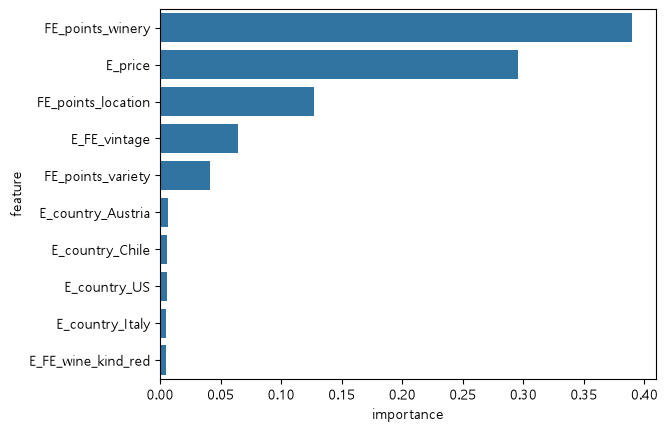

In [14]:
fi = pd.DataFrame({
    'feature' : X.columns,
    'importance' : gs_rf.best_estimator_.feature_importances_,
})

fi = fi.sort_values('importance',ascending=False)[:10]

sns.barplot(data=fi, x= 'importance', y='feature')
plt.show()

In [15]:
from sklearn.metrics import accuracy_score
y_pred_dt = gs_dt.best_estimator_.predict(X_valid)
y_pred_rf = gs_rf.best_estimator_.predict(X_valid)

dt_acc = accuracy_score(y_valid, y_pred_dt)
rf_acc = accuracy_score(y_valid, y_pred_rf)

print("DecisionTree_acc = ", dt_acc)
print("RandomForest_acc = ", rf_acc)

DecisionTree_acc =  0.8089081658186671
RandomForest_acc =  0.8188756359996664


In [16]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(1)

In [17]:
from sklearn.preprocessing import LabelEncoder

model = Sequential([
    Dense(128, activation='relu', input_dim=X_train.shape[1]),
    Dropout(0.3),
    Dense(64,activation='relu'),
    Dense(32,activation='relu'),
    Dense(2,activation='sigmoid'),
])

estop = EarlyStopping(monitor='val_loss', patience=14)
model.compile(
    optimizer='adam',
    metrics = ['accuracy'],
    loss='binary_crossentropy',
)

le = LabelEncoder()

y_train = le.fit_transform(y_train)
y_valid = le.transform(y_valid)

y_train = to_categorical(y_train)
y_valid = to_categorical(y_valid)

history = model.fit(X_train, y_train,
    epochs=30,
    batch_size=128,
    validation_data=(X_valid,y_valid),
    callbacks=[estop],
)

Epoch 1/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7862 - loss: 0.4590 - val_accuracy: 0.8072 - val_loss: 0.4190
Epoch 2/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8023 - loss: 0.4248 - val_accuracy: 0.8097 - val_loss: 0.4138
Epoch 3/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8055 - loss: 0.4185 - val_accuracy: 0.8106 - val_loss: 0.4112
Epoch 4/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8076 - loss: 0.4146 - val_accuracy: 0.8125 - val_loss: 0.4101
Epoch 5/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8079 - loss: 0.4112 - val_accuracy: 0.8115 - val_loss: 0.4083
Epoch 6/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8089 - loss: 0.4100 - val_accuracy: 0.8120 - val_loss: 0.4069
Epoch 7/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8094 - loss: 0.4084 - val_accuracy: 0.8129 - val_loss: 0.4056
Epoch 8/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8108 - loss: 0.4072 - val_accuracy: 0.

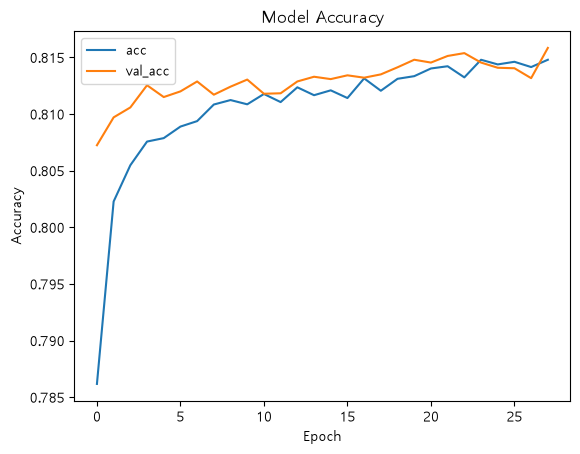

In [18]:

plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(['acc', 'val_acc'])
plt.show() 